# FWER Control with E-values New Yorker Simulations

This notebook produces the plots and results from Section 8 of Family-wise Error Rate Control with E-values (Hartog and Lei). Using existing caption contest data as a ground truth, we run bandit simulations for e-Holm and e-DAG. For e-Holm we are testing the null of an average rating of 1.5, and for e-DAG we are testing the factorial design of various semantic features' significance. See the manuscript for more details on the theory for the tests. We also run a fixed-sample simulation for e-Holm, with no bandit context.

## Loading data and FWER-controlling functions


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

csv_url = 'https://nextml.github.io/caption-contest-data/summaries/895.csv'
df = pd.read_csv(csv_url)

df.head()

,caption,mean,precision,votes,not_funny,somewhat_funny,funny
0,Do you think death rays would be considered el...,1.632287,0.012004,4014,2170,1150,694
1,"Oh sure, now you look at a map.",1.632171,0.018294,1778,976,480,322
2,I've never heard of planet fitness.,1.626694,0.017874,1918,1079,476,363
3,"Wait, was it ""conquer the mall"" or ""conquer th...",1.624266,0.020087,1533,870,369,294
4,"To Bed, Bath, and Beyond!",1.620504,0.013953,2975,1640,824,511


In [ ]:
cat_question = df.caption.apply(lambda x: '?' in x)
cat_exclamation = df.caption.apply(lambda x: '!' in x)
cat_length = df.caption.apply(lambda x: len(x))
median_length = np.median(cat_length)
cat_long = cat_length > median_length

print(cat_question.value_counts())
print(cat_exclamation.value_counts())
print(cat_long.value_counts())
print(cat_length.value_counts().sort_index)


caption
False    3388
True     1570
Name: count, dtype: int64
caption
False    4249
True      709
Name: count, dtype: int64
caption
False    2506
True     2452
Name: count, dtype: int64
<bound method Series.sort_index of caption
35     116
44     113
39     105
42     103
38     102
      ... 
176      1
411      1
158      1
207      1
163      1
Name: count, Length: 176, dtype: int64>


In [ ]:
df['question'] = cat_question
df['exclamation'] = cat_exclamation
df['long'] = cat_long
df['length'] = cat_length
df['p1'] = df.not_funny / df.votes
df['p2'] = df.somewhat_funny / df.votes
df['p3'] = df.funny / df.votes
df['type'] = df.question * 4 + df.exclamation * 2 + df.long
df.head()


,caption,mean,precision,votes,not_funny,somewhat_funny,funny,question,exclamation,long,length,p1,p2,p3,type
0,Do you think death rays would be considered el...,1.632287,0.012004,4014,2170,1150,694,True,False,True,74,0.540608,0.286497,0.172895,5
1,"Oh sure, now you look at a map.",1.632171,0.018294,1778,976,480,322,False,False,False,31,0.548931,0.269966,0.181102,0
2,I've never heard of planet fitness.,1.626694,0.017874,1918,1079,476,363,False,False,False,35,0.562565,0.248175,0.189260,0
3,"Wait, was it ""conquer the mall"" or ""conquer th...",1.624266,0.020087,1533,870,369,294,True,False,True,54,0.567515,0.240705,0.191781,5
4,"To Bed, Bath, and Beyond!",1.620504,0.013953,2975,1640,824,511,False,True,False,25,0.551261,0.276975,0.171765,2


### Holm and DAG Functions

In [ ]:
def e_holm(evals):
  if len(evals) == 0:
    return []

  pairs = sorted(enumerate(evals), key=lambda t: t[1], reverse = True)
  orig_idx = [i for i, _ in pairs]
  e_sorted = [x for _, x in pairs]
  n = len(e_sorted)

  e_adjusted = np.zeros(n)
  e_adjusted[n-1] = e_sorted[n-1]

  k = 1
  E_k = e_sorted[n-k]
  e_adj = float('inf')
  for r in range(1, n):
    i = n - 1 - r
    e = e_sorted[i]
    e_adj = e / (k+1) + E_k * k / (k+1)
    while(e_adj > e_sorted[n - k - 1]):
      E_k = E_k * k / (k+1) + e_sorted[n - k - 1] / (k+1)
      k = k + 1
      e_adj = e / (k+1) + E_k * k / (k+1)
      if k == n:
        break
    e_adjusted[i] = e_adj

  adjusted = np.zeros(n)
  for sorted_pos, i in enumerate(orig_idx):
    adjusted[i] = e_adjusted[sorted_pos]
  return adjusted


In [ ]:
def p_holm(pvals):
  if len(pvals) == 0:
    return []

  pairs = sorted(enumerate(pvals), key=lambda t: t[1])
  orig_idx = [i for i, _ in pairs]
  p_sorted = [x for _, x in pairs]
  n = len(p_sorted)

  p_adjusted = np.zeros(n)
  p_adj = p_sorted[0] * n
  p_adjusted[0] = p_adj

  for i in range(1,n):
    p_i = p_sorted[i] * (n - i)
    if p_i > p_adj:
      p_adj = p_i
    p_adjusted[i] = min(p_adj, 1)

  adjusted = np.zeros(n)
  for sorted_pos, i in enumerate(orig_idx):
    adjusted[i] = p_adjusted[sorted_pos]
  return adjusted

We define e-DAG and p-DAG in a brute force way, since there are only 7 hypotheses. Also, we are not considering the three-way interaction term in our power/fwer calculations so we can always take it to be 1.

In [ ]:
def e_dag(evals, budget = 'primary'):
  # ignore three-way interaction
  adj_evals = np.zeros(7)
  for i in range(3):
    adj_evals[i] = evals[i] / 3
  adj_evals[3] = min((evals[0] + evals[1]) / 3, (evals[0] + evals[3] / 2) / 3, (evals[1] + evals[3] / 2) / 3, evals[3] / 3)
  adj_evals[4] = min((evals[0] + evals[2]) / 3, (evals[0] + evals[4] / 2) / 3, (evals[2] + evals[4] / 2) / 3, evals[4] / 3)
  adj_evals[5] = min((evals[1] + evals[2]) / 3, (evals[1] + evals[5] / 2) / 3, (evals[2] + evals[5] / 2) / 3, evals[5] / 3)
  adj_evals[6] = 1
  return adj_evals

In [ ]:
def p_dag(pvals, budget = 'primary'):
  adj_pvals = np.zeros(7)
  for i in range(3):
    adj_pvals[i] = pvals[i] * 3
  adj_pvals[3] = max(min(pvals[0], pvals[1]) * 3, 3 * pvals[3], min(pvals[0], 2 * pvals[3]) * 3, min(pvals[1], 2 * pvals[3]) * 3)
  adj_pvals[4] = max(min(pvals[0], pvals[2]) * 3, 3 * pvals[4], min(pvals[0], 2 * pvals[4]) * 3, min(pvals[2], 2 * pvals[4]) * 3)
  adj_pvals[5] = max(min(pvals[1], pvals[2]) * 3, 3 * pvals[5], min(pvals[1], 2 * pvals[5]) * 3, min(pvals[2], 2 * pvals[5]) * 3)
  adj_pvals[6] = 1
  return adj_pvals

## Anytime-valid FWER for testing arms

We will test whether an arm has a mean funny rating of more than 1.5 (adjusted on the scale of 0/0.5/1 so the null is 0.25)

In [ ]:
delta = 0.1
kappa = 8
q_grid = np.linspace(0, 0.999, 1000)
def ucb(n, mu):
  beta = np.log(kappa * np.log(2 * n / delta) / np.log(2))
  if mu == 0:
    return (1 - np.exp(- beta / n))
  elif mu == 1:
    return 1
  for q in q_grid[q_grid >= mu]:
    KL = mu * np.log(mu / q) + (1 - mu) * np.log((1 - mu) / (1 - q))
    if (KL > beta / n):
      return (q - 0.001)
  return 1

In [ ]:
n_arms = 50
num_iter = 100000
epsilon = 0.2
mu_0 = 0.25
alpha = 0.05


pulls = np.ones(n_arms)
averages = np.array([np.random.choice([0, 0.5, 1], p=df[['p1','p2','p3']].iloc[i]) for i in range(n_arms)])
ucbs = np.array([ucb(pulls[i], averages[i]) for i in range(n_arms)])

def eval(y, eta = 0.25):
  psi = np.log((1-mu_0) * np.exp(- eta * mu_0) + mu_0 * np.exp(eta * ( 1 - mu_0)))
  return np.exp(eta * (y - mu_0) - psi)

e_processes = np.array([eval(averages[i]) for i in range(n_arms)])
maxima = e_processes

def pull_idx(idx):
  new_rating = np.random.choice([0, 0.5, 1], p = df[['p1', 'p2', 'p3']].iloc[idx])
  n_pulls = pulls[idx]
  averages[idx] = averages[idx] * n_pulls / (n_pulls + 1) + new_rating / (n_pulls + 1)
  pulls[idx] = pulls[idx] + 1
  ucbs[idx] = ucb(pulls[idx], averages[idx])
  return new_rating

reject_e = False
reject_p = False

#print(pulls)
#print(averages)
#print(ucbs)
from tqdm import tqdm
np.random.seed(1)
for s in tqdm(range(num_iter)):
  #best_idx = np.random.choice(np.flatnonzero(averages == averages.max()))
  #pull_idx(best_idx)

  lambda_s = 4 * epsilon ** 2 * 0.05

  pis = np.ones(n_arms) * epsilon / n_arms + np.array(ucbs == ucbs.max()) * (1 - epsilon) / np.sum(ucbs == ucbs.max())

  idx = np.random.choice(np.arange(n_arms), p = pis)
  pull = pull_idx(idx)
  e_processes[idx] = e_processes[idx] * eval(pull)
  maxima = np.maximum(maxima, e_processes)

  #if np.random.uniform() < epsilon:
  #  rand_idx = np.random.choice(np.arange(n_arms))
  #  pull = pull_idx(rand_idx)
  #else:
  #  ucb_idx = np.random.choice(np.flatnonzero(ucbs == ucbs.max()))
  #  pull = pull_idx(ucb_idx)

  if not reject_e:
    best_adj_e = np.max(e_holm(e_processes))
    if best_adj_e > 1 / alpha:
      evals_adj = e_holm(e_processes)
      e_idx = np.argmax(evals_adj)
      print('e-process found a rejection')
      print(f'at pull {s} in index {e_idx} with e-value {best_adj_e} and arm mean {averages[e_idx]}')
      print(evals_adj)
      print('\n')
      reject_e = True

  if not reject_p:
    best_adj_p = np.min(p_holm(1 / maxima))
    if best_adj_p < alpha:
      pvals_adj = p_holm(1 / maxima)
      p_idx = np.argmin(pvals_adj)
      print('p-process found a rejection')
      print(f'at pull {s} in index {p_idx} with p-value {best_adj_p} and arm mean {averages[p_idx]}')
      print(pvals_adj)
      print('\n')
      reject_p = True


print('\n')
print(pulls)
print(averages)
print(ucbs)



  0%|          | 0/100000 [00:00<?, ?it/s]


NameError: name 'e_holm' is not defined

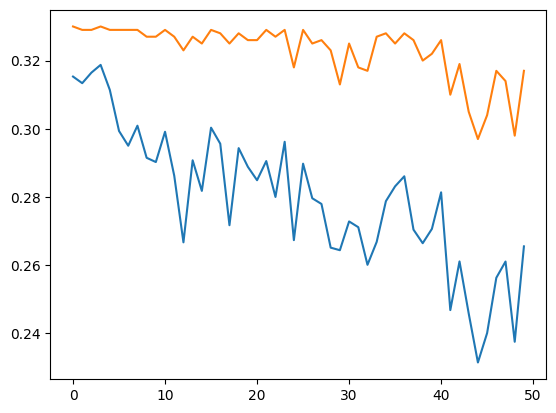

In [ ]:
plt.plot(averages)
plt.plot(ucbs)

In [ ]:
print(e_processes)

[4.37047652e+44 1.33119218e+33 9.90713435e+55 4.00422141e+70
 1.06750033e+25 2.42175752e+06 9.59181585e+03 1.78910882e+07
 8.55095301e+02 3.97233754e+02 1.60229363e+06 3.71869365e+01
 3.08504748e-01 4.57743199e+02 7.34613145e+00 5.70389714e+06
 2.41931533e+04 6.32471687e-01 5.60048285e+03 1.75216365e+02
 2.28674713e+01 2.57689140e+02 3.50270867e+00 3.04553215e+04
 2.61629289e-01 1.38578277e+02 3.49179407e+00 2.17038802e+00
 2.64090358e-01 1.30947294e-01 7.53621541e-01 4.83523919e-01
 1.21184048e-01 3.65416010e-01 2.47453472e+00 1.12910984e+01
 2.94082689e+01 5.33237317e-01 2.66082761e-01 4.97060621e-01
 5.76543566e+00 3.72467624e-02 1.44185439e-01 2.07728727e-02
 1.11885369e-02 2.01204550e-02 9.86531015e-02 1.05637941e-01
 9.75321442e-03 1.94357498e-01]


In [ ]:
e_holm(e_processes)

array([0.93370128, 0.93746858, 0.93370128, 0.93370128, 0.93746858,
       0.93370128, 0.93746858, 0.93746858, 0.93746858, 0.93370128,
       0.94173749, 0.93370128, 0.93370128, 0.93370128, 0.93370128,
       0.93370128, 0.93370128, 0.93370128, 0.93746858, 0.93932884,
       0.93370128, 0.94173749, 0.94173749, 0.93370128, 0.93370128,
       0.93370128, 0.93370128, 0.93370128, 0.93370128, 0.93746858,
       0.93746858, 0.93370128, 0.94173749, 0.93370128, 0.94173749,
       0.93370128, 0.93370128, 0.93370128, 0.93370128, 0.93746858,
       0.93370128, 0.93370128, 0.93746858, 0.93370128, 0.93370128,
       0.93370128, 0.93370128, 0.93746858, 0.93746858, 0.93370128])

In [ ]:
1 / p_holm(1 / maxima)

array([4.48498294e+21, 2.45390693e+32, 2.05492024e+75, 6.39443943e+71,
       1.80932091e+19, 7.90699804e+16, 2.41579868e+03, 7.45545933e+10,
       1.11354217e+00, 7.36777185e+05, 7.79517895e+01, 1.68647554e+01,
       1.00000000e+00, 5.95193670e+01, 6.90123849e+03, 1.69422809e+09,
       3.63025075e+01, 1.00000000e+00, 1.00000000e+00, 1.38439070e+01,
       2.79738373e+00, 2.23231283e+01, 1.05532434e+00, 1.00000000e+00,
       1.00000000e+00, 1.18004750e+00, 1.00000000e+00, 1.00000000e+00,
       1.03498498e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.18987443e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 2.35122000e+00,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00, 1.00000000e+00, 1.00000000e+00,
       1.00000000e+00, 1.00000000e+00])

In [ ]:
np.mean(np.log(e_holm(maxima)) - np.log(1 / p_holm(1 / maxima)))

np.float64(0.4568459370958267)

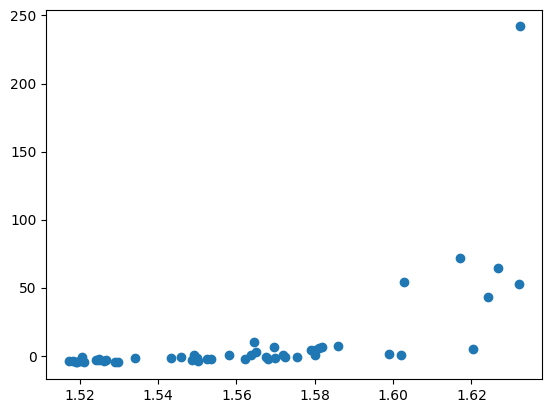

In [ ]:
plt.scatter(df['mean'][:n_arms], np.log(e_holm(e_processes)))

In [ ]:
print(ucbs)

[0.40859    0.542456   0.546452   0.542456   0.501497   0.526472
 0.516482   0.54845    0.51731288 0.539459   0.542456   0.539459
 0.51731288 0.539459   0.537461   0.543455   0.542456   0.535463
 0.542456   0.542456   0.542456   0.514484   0.545453   0.527471
 0.542456   0.539459   0.539459   0.447551   0.510488   0.537461
 0.53846    0.517481   0.53846    0.53846    0.531467   0.546452
 0.536462   0.539459   0.552446   0.535463   0.526472   0.54845
 0.541457   0.51731288 0.549449   0.542456   0.543455   0.541457
 0.533465   0.516482  ]


In [ ]:
np.argmax(np.ones(10))

np.int64(0)

In [ ]:
lambda_s = 4 * epsilon ** 2 * 0.05
ratio = lambda_s / (epsilon / n_arms)
ratio * 0.75 / (ratio ** 2 / 8)

14.999999999999996

In [ ]:
np.mean(e_holm(e_processes) > 1 / alpha)

np.float64(0.32)

In [ ]:
np.mean(p_holm(1 / maxima) < alpha)

np.float64(0.34)

# Simulation

In [ ]:
def run_bandits(indices, num_steps, seed = 0):
  num_iter = num_steps
  epsilon = 0.4
  mu_0 = 0.25
  alpha = 0.05

  df_indices = df.iloc[indices].reset_index()
  n_arms = len(indices)


  pulls = np.ones(n_arms)
  averages = np.array([np.random.choice([0, 0.5, 1], p=df_indices[['p1','p2','p3']].iloc[i]) for i in range(n_arms)])
  ucbs = np.array([ucb(pulls[i], averages[i]) for i in range(n_arms)])

  def eval(y, eta = 0.25):
    psi = np.log((1-mu_0) * np.exp(- eta * mu_0) + mu_0 * np.exp(eta * ( 1 - mu_0)))
    return np.exp(eta * (y - mu_0) - psi)

  e_processes = np.array([eval(averages[i]) for i in range(n_arms)])
  maxima = e_processes

  def pull_idx(idx):
    new_rating = np.random.choice([0, 0.5, 1], p = df_indices[['p1', 'p2', 'p3']].iloc[idx])
    n_pulls = pulls[idx]
    averages[idx] = averages[idx] * n_pulls / (n_pulls + 1) + new_rating / (n_pulls + 1)
    pulls[idx] = pulls[idx] + 1
    ucbs[idx] = ucb(pulls[idx], averages[idx])
    return new_rating

  reject_e = False
  pulls_e = (float('inf'), float('inf'))
  reject_p = False
  pulls_p = (float('inf'), float('inf'))
  reject_ep = False
  pulls_ep = (float('inf'), float('inf'))
  reject_em = False
  pulls_em = (float('inf'), float('inf'))

  #print(pulls)
  #print(averages)
  #print(ucbs)
  from tqdm import tqdm
  np.random.seed(seed)
  for s in tqdm(range(num_iter)):
    #best_idx = np.random.choice(np.flatnonzero(averages == averages.max()))
    #pull_idx(best_idx)

    lambda_s = 4 * epsilon ** 2 * 0.05

    pis = np.ones(n_arms) * epsilon / n_arms + np.array(ucbs == ucbs.max()) * (1 - epsilon) / np.sum(ucbs == ucbs.max())

    idx = np.random.choice(np.arange(n_arms), p = pis)
    pull = pull_idx(idx)
    e_processes[idx] = e_processes[idx] * eval(pull)
    maxima = np.maximum(maxima, e_processes)

    if not reject_e:
      best_adj_e = np.max(e_holm(e_processes))
      if best_adj_e > 1 / alpha:
        evals_adj = e_holm(e_processes)
        e_idx = np.argmax(evals_adj)
        #print('e-process found a rejection')
        #print(f'at pull {s} in index {e_idx} with e-value {best_adj_e} and arm mean {averages[e_idx]}')
        #print(evals_adj)
        #print('\n')
        pulls_arm = pulls[e_idx]
        pulls_e = (s, pulls_arm)
        reject_e = True

    if not reject_p:
      best_adj_p = np.min(p_holm(1 / maxima))
      if best_adj_p < alpha:
        pvals_adj = p_holm(1 / maxima)
        p_idx = np.argmin(pvals_adj)
        #print('p-process found a rejection')
        #print(f'at pull {s} in index {p_idx} with p-value {best_adj_p} and arm mean {averages[p_idx]}')
        #print(pvals_adj)
        #print('\n')
        pulls_arm = pulls[p_idx]
        pulls_p = (s, pulls_arm)
        reject_p = True

    if not reject_ep:
      best_adj_ep = np.min(p_holm(e_processes))
      if best_adj_ep < alpha:
        epvals_adj = p_holm(e_processes)
        ep_idx = np.argmin(epvals_adj)
        #print('p-process found a rejection')
        #print(f'at pull {s} in index {p_idx} with p-value {best_adj_p} and arm mean {averages[p_idx]}')
        #print(pvals_adj)
        #print('\n')
        pulls_arm = pulls[ep_idx]
        pulls_ep = (s, pulls_arm)
        reject_ep = True

    if not reject_em:
      best_adj_em = np.max(e_holm(maxima))
      if best_adj_em > 1 / alpha:
        emvals_adj = e_holm(maxima)
        em_idx = np.argmax(emvals_adj)
        #print('p-process found a rejection')
        #print(f'at pull {s} in index {p_idx} with p-value {best_adj_p} and arm mean {averages[p_idx]}')
        #print(pvals_adj)
        #print('\n')
        pulls_arm = pulls[em_idx]
        pulls_em = (s, pulls_arm)
        reject_em = True

  return pulls, averages, ucbs, maxima, e_processes, pulls_p, pulls_e, pulls_ep, pulls_em

In [ ]:
run_bandits(range(50), 10000)

100%|██████████| 10000/10000 [00:19<00:00, 519.48it/s]


(array([278., 136., 453., 276., 399., 269., 191., 253., 193.,  98., 178.,
         90., 225., 146., 249., 245., 325., 476., 393., 200., 283.,  97.,
        243., 288., 177.,  92., 154., 143.,  97.,  90., 138., 183., 205.,
        119., 182., 268., 174., 135., 100., 116., 185., 220., 198.,  93.,
         83., 154., 312., 178.,  86., 184.]),
 array([0.29316547, 0.25367647, 0.31677704, 0.29528986, 0.31203008,
        0.28438662, 0.28010471, 0.29249012, 0.27979275, 0.23469388,
        0.27808989, 0.21666667, 0.28666667, 0.26369863, 0.29116466,
        0.29183673, 0.30461538, 0.31827731, 0.31170483, 0.275     ,
        0.30035336, 0.24226804, 0.29218107, 0.30034722, 0.26836158,
        0.20108696, 0.26948052, 0.26223776, 0.23195876, 0.21666667,
        0.25      , 0.27322404, 0.2804878 , 0.24789916, 0.27472527,
        0.29664179, 0.27011494, 0.26296296, 0.215     , 0.24137931,
        0.27837838, 0.28863636, 0.27020202, 0.22043011, 0.18072289,
        0.26623377, 0.30448718, 0.27808989, 0.

In [ ]:
# simulation without nulls
num_iter = 100
pulls_es = np.zeros(num_iter)
pulls_ps = np.zeros(num_iter)
pulls_ems = np.zeros(num_iter)
power_es = np.zeros(num_iter)
power_ps = np.zeros(num_iter)
power_eps = np.zeros(num_iter)
power_ems = np.zeros(num_iter)
for i in range(num_iter):
  pulls, averages, ucbs, maxima, e_processes, pulls_p, pulls_e, pulls_em = run_bandits(range(50), 10000, i)
  power_es[i] = np.mean(e_holm(e_processes) > 1 / alpha)
  power_ps[i] = np.mean(p_holm(1 / maxima) < alpha)
  power_eps[i] = np.mean(p_holm(1/e_processes) < alpha)
  power_ems[i] = np.mean(e_holm(maxima) > 1/alpha)
  pulls_es[i] = pulls_e
  pulls_ps[i] = pulls_p
  pulls_ems[i] = pulls_em

100%|██████████| 10000/10000 [00:15<00:00, 655.16it/s]


In [ ]:
n = 50
n_1 = 20
n_0 = n - n_1
null_indices=df[df['mean'] <= 1.5].index[:n_0]
mix_indices=list(range(n_1)) + list(null_indices)

num_steps = 10000
alpha = 0.05

# simulation with nulls
num_iter = 100
pulls_es = np.zeros((num_iter, 2))
pulls_ps = np.zeros((num_iter, 2))
pulls_eps = np.zeros((num_iter, 2))
pulls_ems = np.zeros((num_iter, 2))
power_es = np.zeros(num_iter)
power_ps = np.zeros(num_iter)
power_eps = np.zeros(num_iter)
power_ems = np.zeros(num_iter)
fwer_es = np.zeros(num_iter)
fwer_ps = np.zeros(num_iter)
fwer_eps = np.zeros(num_iter)
fwer_ems = np.zeros(num_iter)
for i in range(num_iter):
  pulls, averages, ucbs, maxima, e_processes, pulls_p, pulls_e, pulls_ep, pulls_em = run_bandits(mix_indices, num_steps, i)
  power_es[i] = np.mean(e_holm(e_processes)[:n_1] > 1 / alpha)
  power_ps[i] = np.mean(p_holm(1 / maxima)[:n_1] < alpha)
  power_eps[i] = np.mean(p_holm(1/e_processes)[:n_1] < alpha)
  power_ems[i] = np.mean(e_holm(maxima)[:n_1] > 1/alpha)

  fwer_es[i] = np.any(e_holm(e_processes)[n_1:] > 1 / alpha)
  fwer_ps[i] = np.any(p_holm(1 / maxima)[n_1:] < alpha)
  fwer_eps[i] = np.any(p_holm(1/e_processes)[n_1:] < alpha)
  fwer_ems[i] = np.any(e_holm(maxima)[n_1:] > 1/alpha)

  pulls_es[i] = pulls_e
  pulls_ps[i] = pulls_p
  pulls_eps[i] = pulls_ep
  pulls_ems[i] = pulls_em

100%|██████████| 10000/10000 [00:15<00:00, 651.24it/s]


In [ ]:
print(f'Power for e-Holm: {np.mean(power_es)}')
print(f'Power for p-Holm: {np.mean(power_ps)}')
print(f'Power for ep-Holm: {np.mean(power_eps)}')
print(f'Power for em-Holm: {np.mean(power_ems)}')
print(f'FWER for e-Holm: {np.mean(fwer_es)}')
print(f'FWER for p-Holm: {np.mean(fwer_ps)}')
print(f'FWER for ep-Holm: {np.mean(fwer_eps)}')
print(f'FWER for em-Holm: {np.mean(fwer_ems)}')

Power for e-Holm: 0.08450000000000003
Power for p-Holm: 0.09900000000000002
Power for ep-Holm: 0.08
Power for em-Holm: 0.1085
FWER for e-Holm: 0.0
FWER for p-Holm: 0.0
FWER for ep-Holm: 0.0
FWER for em-Holm: 0.0


In [ ]:
print(f'Average Rejection Time for e-Holm: {np.mean(pulls_es[:,0][pulls_ps[:,0] < float('inf')])}')
print(f'Average Rejection Time for p-Holm: {np.mean(pulls_ps[:,0][pulls_ps[:,0] < float('inf')])}')
print(f'Average Rejection Time for em-Holm: {np.mean(pulls_ems[:,0][pulls_ps[:,0] < float('inf')])}')

print(f'Average Pulls for e-Holm: {np.mean(pulls_es[:,1][pulls_ps[:,1] < float('inf')])}')
print(f'Average Pulls for p-Holm: {np.mean(pulls_ps[:,1][pulls_ps[:,1] < float('inf')])}')
print(f'Average Pulls for em-Holm: {np.mean(pulls_ems[:,1][pulls_ps[:,1] < float('inf')])}')

Average Rejection Time for e-Holm: 6472.8105263157895
Average Rejection Time for p-Holm: 6555.242105263158
Average Rejection Time for em-Holm: 6393.336842105263
Average Pulls for e-Holm: 412.0736842105263
Average Pulls for p-Holm: 420.4
Average Pulls for em-Holm: 405.09473684210525


In [ ]:
print(f'Average Stopping Time Ratio for e-Holm vs ep-Holm: {np.mean(np.minimum(pulls_es[:,0], 10000)/np.minimum(pulls_ps[:,0], 10000))}')
#print(f'Average Stopping Time Ratio for p-Holm vs ep-Holm: {np.mean(np.minimum(pulls_ps[:,0], 10000)/np.minimum(pulls_eps[:,0], 10000))}')
print(f'Average Stopping Time Ratio for em-Holm vs ep-Holm: {np.mean(np.minimum(pulls_ems[:,0], 10000)/np.minimum(pulls_ps[:,0], 10000))}')

print(f'Improvement Probability for e-Holm vs ep-Holm: {np.mean(pulls_es[:,0] < pulls_ps[:,0])}')
#print(f'Improvement Probability for p-Holm vs ep-Holm: {np.mean(pulls_ps[:,0] < pulls_eps[:,0])}')
print(f'Improvement Probability for em-Holm vs ep-Holm: {np.mean(pulls_ems[:,0] < pulls_ps[:,0])}')

Average Stopping Time Ratio for e-Holm vs ep-Holm: 0.9882600841063567
Average Stopping Time Ratio for em-Holm vs ep-Holm: 0.9748737926910646
Improvement Probability for e-Holm vs ep-Holm: 0.79
Improvement Probability for em-Holm vs ep-Holm: 0.96


In [ ]:
print(f'Average Stopping Time Ratio for e-Holm vs ep-Holm: {np.mean(np.minimum(pulls_es[:,1], 10000)/np.minimum(pulls_ps[:,1], 10000))}')
#print(f'Average Stopping Time Ratio for p-Holm vs ep-Holm: {np.mean(np.minimum(pulls_ps[:,1], 10000)/np.minimum(pulls_eps[:,1], 10000))}')
print(f'Average Stopping Time Ratio for p-Holm vs ep-Holm: {np.mean(np.minimum(pulls_ems[:,1], 10000)/np.minimum(pulls_ps[:,1], 10000))}')

print(f'Improvement Probability for e-Holm vs ep-Holm: {np.mean(pulls_es[:,1] < pulls_ps[:,1])}')
#print(f'Improvement Probability for p-Holm vs ep-Holm: {np.mean(pulls_ps[:,1] < pulls_eps[:,1])}')
print(f'Improvement Probability for em-Holm vs ep-Holm: {np.mean(pulls_ems[:,1] < pulls_ps[:,1])}')

Average Stopping Time Ratio for e-Holm vs ep-Holm: 0.9809004359583419
Average Stopping Time Ratio for p-Holm vs ep-Holm: 0.9555384033468628
Improvement Probability for e-Holm vs ep-Holm: 0.78
Improvement Probability for em-Holm vs ep-Holm: 0.95


In [ ]:
print(f'Average Ratio when Unequal for e-Holm vs p-Holm: {np.mean(np.minimum(pulls_es[pulls_es < pulls_ps], 10000)/np.minimum(pulls_ps[pulls_es < pulls_ps], 10000))}')
print(f'Average Ratio when Unequal for em-Holm vs p-Holm: {np.mean(np.minimum(pulls_ems[pulls_ems < pulls_ps], 10000)/np.minimum(pulls_ps[pulls_ems < pulls_ps], 10000))}')

Average Ratio when Unequal for e-Holm vs p-Holm: 0.9950063817493782
Average Ratio when Unequal for em-Holm vs p-Holm: 0.9078251982571857


In [ ]:
print(f'Probability of no rejection for p-Holm: {np.mean(pulls_ps == float('inf'))}')
print(f'Probability of no rejection for e-Holm: {np.mean(pulls_es == float('inf'))}')
print(f'Probability of no rejection for em-Holm: {np.mean(pulls_ems == float('inf'))}')

Probability of no rejection for p-Holm: 0.84
Probability of no rejection for e-Holm: 0.84
Probability of no rejection for em-Holm: 0.81


In [ ]:
pulls, averages, ucbs, maxima, e_processes, pulls_p, pulls_e, pulls_em = run_bandits(mix_indices, 10000)

100%|██████████| 10000/10000 [00:18<00:00, 548.89it/s]


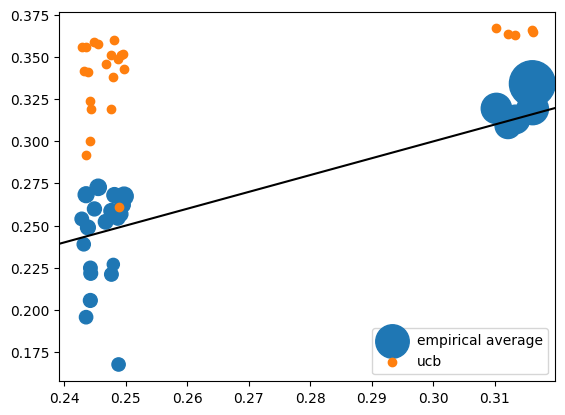

In [ ]:
means = df.iloc[mix_indices]['mean'] / 2 - 0.5
plt.scatter(means, averages, label = 'empirical average', s = pulls / 2)
plt.scatter(means, ucbs, label = 'ucb')
plt.axline((0.25, 0.25), slope = 1, color = 'black')
plt.legend()

In [ ]:
pulls

array([1029., 2172.,  845.,  695.,  953.,  344.,  244.,  220.,  182.,
        218.,  235.,  152.,  190.,  230.,  220.,  275.,  202.,  194.,
        189.,  197.,  227.,  259.,  184.,  180.,  189.])

## e-DAG simulation

In [ ]:
df[df['type'] == 0]

,caption,mean,precision,votes,not_funny,somewhat_funny,funny,question,exclamation,long,length,p1,p2,p3,type
1,"Oh sure, now you look at a map.",1.632171,0.018294,1778,976,480,322,False,False,False,31,0.548931,0.269966,0.181102,0
2,I've never heard of planet fitness.,1.626694,0.017874,1918,1079,476,363,False,False,False,35,0.562565,0.248175,0.189260,0
8,We’re good; they’re all looking at their phones.,1.599002,0.016871,2005,1135,539,331,False,False,False,48,0.566085,0.268828,0.165087,0
9,"Dairy Queen, that must be their leader",1.585814,0.014332,2721,1557,734,430,False,False,False,38,0.572216,0.269754,0.158030,0
12,I assume their leader is this “Burger King.”,1.580120,0.015166,2334,1322,670,342,False,False,False,44,0.566410,0.287061,0.146530,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4932,Hot Topic and Spencer’s. We’ll fit right in.,1.039474,0.022484,76,73,3,0,False,False,False,44,0.960526,0.039474,0.000000,0
4935,When they don’t ship to your home address.,1.037975,0.021642,79,76,3,0,False,False,False,42,0.962025,0.037975,0.000000,0
4939,You should have just parked on top of Dillard's.,1.036585,0.020860,82,79,3,0,False,False,False,48,0.963415,0.036585,0.000000,0
4949,Let's stop by the Cinnabon on our way back,1.025641,0.018013,78,76,2,0,False,False,False,42,0.974359,0.025641,0.000000,0


In [ ]:
contrast_action = np.zeros((8, 3))
for i in range(2):
  for j in range(2):
    for k in range(2):
      a = 4 * i + 2 * j + k
      contrast_action[a,0] = -1 + 2 * i
      contrast_action[a,1] = -1 + 2 * j
      contrast_action[a,2] = -1 + 2 * k

print(contrast_action)

[[-1. -1. -1.]
 [-1. -1.  1.]
 [-1.  1. -1.]
 [-1.  1.  1.]
 [ 1. -1. -1.]
 [ 1. -1.  1.]
 [ 1.  1. -1.]
 [ 1.  1.  1.]]


In [ ]:
for a in range(8):
  print(f'Question ({contrast_action[a,0]}), Exclamation ({contrast_action[a,1]}), Long ({contrast_action[a,2]}):')
  print(f'Number of type: {df[df['type'] == a].shape}')
  print(f'Mean: {df[df['type'] == a]['mean'].mean()}')
  print('\n')

Question (-1.0), Exclamation (-1.0), Long (-1.0):
Number of type: (1352, 15)
Mean: 1.1929321336398138


Question (-1.0), Exclamation (-1.0), Long (1.0):
Number of type: (1491, 15)
Mean: 1.1797376079046094


Question (-1.0), Exclamation (1.0), Long (-1.0):
Number of type: (264, 15)
Mean: 1.1804870010531383


Question (-1.0), Exclamation (1.0), Long (1.0):
Number of type: (281, 15)
Mean: 1.1616222318245006


Question (1.0), Exclamation (-1.0), Long (-1.0):
Number of type: (829, 15)
Mean: 1.18911323148423


Question (1.0), Exclamation (-1.0), Long (1.0):
Number of type: (577, 15)
Mean: 1.1752639679474117


Question (1.0), Exclamation (1.0), Long (-1.0):
Number of type: (61, 15)
Mean: 1.1890102307616686


Question (1.0), Exclamation (1.0), Long (1.0):
Number of type: (103, 15)
Mean: 1.1912141087505907




In [ ]:
beta_contrasts = np.array([
    # beta_1 = mu100 - mu000
    [-1,  0,  0,  0,  1,  0,  0,  0],

    # beta_2 = mu010 - mu000
    [-1,  0,  1,  0,  0,  0,  0,  0],

    # beta_3 = mu001 - mu000
    [-1,  1,  0,  0,  0,  0,  0,  0],

    # beta_12 = mu110 - mu100 - mu010 + mu000
    [ 1,  0, -1,  0, -1,  0,  1,  0],

    # beta_13 = mu101 - mu100 - mu001 + mu000
    [ 1, -1,  0,  0, -1,  1,  0,  0],

    # beta_23 = mu011 - mu010 - mu001 + mu000
    [ 1, -1, -1,  1,  0,  0,  0,  0],

    # beta_123 = mu111 - mu110 - mu101 - mu011 + mu100 + mu010 + mu001 - mu000
    [-1,  1,  1, -1,  1, -1, -1,  1],
], dtype=int)

In [ ]:
np.random.seed(0)
indices = []
for a in range(8):
  a_indices = np.random.choice(df[df['type'] == a].index, 6, replace = False)
  indices.extend(a_indices)
df_dag = df.iloc[indices].reset_index()

In [ ]:
type_means = df_dag.groupby('type').agg({'mean':'mean'})
betas = beta_contrasts @ type_means
print(type_means)
print(betas)

          mean
type          
0     1.187190
1     1.274874
2     1.202926
3     1.168192
4     1.252901
5     1.201775
6     1.153857
7     1.271229
       mean
0  0.065711
1  0.015736
2  0.087683
3 -0.114781
4 -0.138810
5 -0.122417
6  0.290916


In [ ]:
def run_bandits_balanced(num_per_arm, num_steps, seed = 0, arm_seed = 0):
  np.random.seed(arm_seed)
  indices = []
  for a in range(8):
    a_indices = np.random.choice(df[df['type'] == a].index, num_per_arm)
    indices.extend(a_indices)

  num_iter = num_steps
  epsilon = 0.4
  mu_0 = 0.25
  alpha = 0.05

  df_indices = df.iloc[indices].reset_index()
  n_arms = len(indices)

  type_means = df_indices.groupby('type').agg({'mean':'mean'})
  betas = beta_contrasts @ type_means

  df_sim = pd.DataFrame(columns = ['pulls', 'averages', 'ucbs', 'type'])


  df_sim.pulls = np.ones(n_arms)
  df_sim.averages = np.array([np.random.choice([0, 0.5, 1], p=df_indices[['p1','p2','p3']].iloc[i]) for i in range(n_arms)])
  df_sim.ucbs = np.array([ucb(df_sim.loc[i, 'pulls'], df_sim.loc[i, 'averages']) for i in range(n_arms)])
  df_sim['type'] = df_indices['type']

  type_averages = df_sim.groupby('type').agg({'averages':'mean'})
  beta_averages = beta_contrasts @ type_averages

  def eval(y, idx, pi, lam = 0.05, side = 1):
    type_idx = df_indices['type'][idx]
    beta_values = np.array([a[0] for a in beta_averages.values])
    psi = beta_values + beta_contrasts[:,type_idx] * (1 / num_per_arm) / pi * (y - df_sim.averages[idx])
    return (1 + side * lam * psi)

  e_processes_pos = np.ones(7)
  e_processes_neg = np.ones(7)
  e_processes = np.ones(7)
  maxima = e_processes

  def pull_idx(idx, pi):
    new_rating = np.random.choice([0, 0.5, 1], p = df_indices[['p1', 'p2', 'p3']].iloc[idx])
    n_pulls = df_sim.loc[idx, 'pulls']
    e_processes_pos[:7] = e_processes * eval(new_rating, idx, pi, side = 1)
    e_processes_neg[:7] = e_processes * eval(new_rating, idx, pi, side = -1)
    e_processes[:7] = np.maximum(e_processes_pos, e_processes_neg)
    maxima[0:7] = np.maximum(maxima, e_processes)
    df_sim.loc[idx, 'averages'] = df_sim.loc[idx, 'averages'] * n_pulls / (n_pulls + 1) + new_rating / (n_pulls + 1)
    df_sim.loc[idx, 'pulls'] = df_sim.loc[idx, 'pulls'] + 1
    df_sim.loc[idx, 'ucbs'] = ucb(df_sim.loc[idx,'pulls'], df_sim.loc[idx, 'averages'])
    type_averages[:8] = df_sim.groupby('type').agg({'averages':'mean'})
    beta_averages[:7] = beta_contrasts @ type_averages
    #return new_rating

  reject_e = False
  pulls_e = float('inf')
  e_arm = None
  reject_p = False
  pulls_p = float('inf')
  reject_em = False
  pulls_em = float('inf')
  reject_ep = False
  pulls_ep = float('inf')

  from tqdm import tqdm
  np.random.seed(seed)
  for s in tqdm(range(num_iter)):
    #best_idx = np.random.choice(np.flatnonzero(averages == averages.max()))
    #pull_idx(best_idx)

    lambda_s = 4 * epsilon ** 2 * 0.05

    pis = np.ones(n_arms) * epsilon / n_arms + np.array(df_sim.ucbs == df_sim.ucbs.max()) * (1 - epsilon) / np.sum(df_sim.ucbs == df_sim.ucbs.max())

    idx = np.random.choice(np.arange(n_arms), p = pis)
    pull = pull_idx(idx, pis[idx])

    #if np.random.uniform() < epsilon:
    #  rand_idx = np.random.choice(np.arange(n_arms))
    #  pull = pull_idx(rand_idx)
    #else:
    #  ucb_idx = np.random.choice(np.flatnonzero(ucbs == ucbs.max()))
    #  pull = pull_idx(ucb_idx)

    if not reject_e:
      best_adj_e = np.max(e_dag(e_processes)[3:6])
      if best_adj_e > 1 / alpha:
        evals_adj = e_dag(e_processes)
        e_idx = np.argmax(evals_adj[3:6])
        #print('e-process found a rejection')
        #print(f'at pull {s} in index {e_idx} with e-value {best_adj_e} and arm mean {averages[e_idx]}')
        #print(evals_adj)
        #print('\n')
        pulls_e = s
        reject_e = True
        e_arm = e_idx


    if not reject_p:
      best_adj_p = np.min(p_dag(1 / maxima)[3:6])
      if best_adj_p < alpha:
        pvals_adj = p_dag(1 / maxima)
        p_idx = np.argmin(pvals_adj[3:6])
        #print('p-process found a rejection')
        #print(f'at pull {s} in index {p_idx} with p-value {best_adj_p} and arm mean {averages[p_idx]}')
        #print(pvals_adj)
        #print('\n')
        pulls_p = s
        reject_p = True

    if not reject_em:
      best_adj_em = np.max(e_dag(maxima)[3:6])
      if best_adj_em > 1 / alpha:
        emvals_adj = e_dag(maxima)
        em_idx = np.argmax(emvals_adj[3:6])
        #print('p-process found a rejection')
        #print(f'at pull {s} in index {p_idx} with p-value {best_adj_p} and arm mean {averages[p_idx]}')
        #print(pvals_adj)
        #print('\n')
        pulls_em = s
        reject_em = True

    if not reject_ep:
      best_adj_ep = np.min(p_dag(1 / e_processes)[3:6])
      if best_adj_ep < alpha:
        epvals_adj = p_dag(1 / e_processes)
        p_idx = np.argmin(pvals_adj[3:6])
        #print('p-process found a rejection')
        #print(f'at pull {s} in index {p_idx} with p-value {best_adj_p} and arm mean {averages[p_idx]}')
        #print(pvals_adj)
        #print('\n')
        pulls_ep = s
        reject_ep = True

  return df_sim, maxima, e_processes, beta_averages, pulls_p, pulls_e, pulls_em, pulls_ep, e_arm

In [ ]:
df_sim, maxima, e_processes, beta_averages, pulls_p, pulls_e, pulls_em, pulls_ep, e_arm = run_bandits_balanced(6, 10000)

pulls       1.000000
averages    0.000000
ucbs        0.971078
type        0.000000
Name: 0, dtype: float64
   averages
0 -0.083333
1  0.000000
2 -0.083333
3  0.083333
4  0.166667
5  0.000000
6 -0.166667
[0.59583333 0.6        0.59583333 1.40416667 1.40833333 1.4
 0.59166667]


100%|██████████| 10000/10000 [00:44<00:00, 224.36it/s]


In [ ]:
print(pulls_p)
print(pulls_e)
print(pulls_em)
print(pulls_ep)

285
257
257
285


In [ ]:
print(betas)
print(beta_averages)
print(e_processes)

       mean
0  0.065711
1  0.015736
2  0.087683
3 -0.114781
4 -0.138810
5 -0.122417
6  0.290916
   averages
0  0.024487
1  0.021741
2  0.013802
3 -0.020265
4 -0.036395
5 -0.018753
6  0.106944
[4.05980340e+052 2.48329340e+054 5.84257708e+053 1.25285789e+103
 1.12697783e+102 3.02643106e+106 7.71178403e+215]


In [ ]:
evals = np.array([1,2,3,4,5,6,7])
print(e_dag(evals))
print(1/p_dag(1 / evals))

[0.33333333 0.66666667 1.         1.         1.16666667 1.66666667
 1.        ]
[0.33333333 0.66666667 1.         0.66666667 1.         1.
 1.        ]


In [ ]:
num_per_arm = 6
num_steps = 1000
alpha = 0.05

# simulation with nulls
num_iter = 100
pulls_es = np.zeros(num_iter)
pulls_ps = np.zeros(num_iter)
pulls_ems = np.zeros(num_iter)
pulls_eps = np.zeros(num_iter)
power_es = np.zeros(num_iter)
power_ps = np.zeros(num_iter)
power_eps = np.zeros(num_iter)
power_ems = np.zeros(num_iter)
e_arms = np.zeros(num_iter)
#fwer_es = np.zeros(num_iter)
#fwer_ps = np.zeros(num_iter)
#fwer_eps = np.zeros(num_iter)
#fwer_ems = np.zeros(num_iter)
for i in range(num_iter):
  df_sim, maxima, e_processes, beta_averages, pulls_p, pulls_e, pulls_em, pulls_ep, e_arm = run_bandits_balanced(num_per_arm, num_steps, seed = i)
  power_es[i] = np.mean(e_dag(e_processes)[3:6] > 1 / alpha)
  power_ps[i] = np.mean(p_dag(1 / maxima)[3:6] < alpha)
  power_eps[i] = np.mean(p_dag(1/e_processes)[3:6] < alpha)
  power_ems[i] = np.mean(e_dag(maxima)[3:6] > 1/alpha)

  pulls_es[i] = pulls_e
  pulls_ps[i] = pulls_p
  pulls_ems[i] = pulls_em
  pulls_eps[i] = pulls_ep

  e_arms[i] = e_arm

100%|██████████| 1000/1000 [00:06<00:00, 165.53it/s]


In [ ]:
print(f'Power for e-Holm: {np.mean(power_es)}')
print(f'Power for p-Holm: {np.mean(power_ps)}')
print(f'Power for ep-Holm: {np.mean(power_eps)}')
print(f'Power for em-Holm: {np.mean(power_ems)}')

Power for e-Holm: 1.0
Power for p-Holm: 1.0
Power for ep-Holm: 1.0
Power for em-Holm: 1.0


In [ ]:
print(f'Average Stopping Time Ratio for e-DAG vs p-DAG: {np.mean(np.minimum(pulls_es, 10000)/np.minimum(pulls_ps, 10000))}')
print(f'Average Stopping Time Ratio for em-DAG vs p-DAG: {np.mean(np.minimum(pulls_ems, 10000)/np.minimum(pulls_ps, 10000))}')
print('\n')
print(f'Improvement Probability for e-DAG vs p-DAG: {np.mean(pulls_es < pulls_ps)}')
print(f'Improvement Probability for p-DAG vs e-DAG: {np.mean(pulls_es > pulls_ps)}')
print(f'Improvement Probability for em-DAG vs p-DAG: {np.mean(pulls_ems < pulls_ps)}')
print(f'Improvement Probability for p-DAG vs em-DAG: {np.mean(pulls_ems > pulls_ps)}')
print('\n')
print(f'Average Ratio when Unequal for e-DAG vs p-DAG: {np.mean(np.minimum(pulls_es[pulls_es < pulls_ps], 10000)/np.minimum(pulls_ps[pulls_es < pulls_ps], 10000))}')
print(f'Average Ratio when Unequal for e-DAG vs ep-DAG: {np.mean(np.minimum(pulls_es[pulls_es < pulls_eps], 10000)/np.minimum(pulls_ps[pulls_es < pulls_eps], 10000))}')

Average Stopping Time Ratio for e-DAG vs p-DAG: 0.8969409202854335
Average Stopping Time Ratio for em-DAG vs p-DAG: 0.8969409202854335


Improvement Probability for e-DAG vs p-DAG: 0.93
Improvement Probability for p-DAG vs e-DAG: 0.0
Improvement Probability for em-DAG vs p-DAG: 0.93
Improvement Probability for p-DAG vs em-DAG: 0.0


Average Ratio when Unequal for e-DAG vs p-DAG: 0.8891837852531543
Average Ratio when Unequal for e-DAG vs ep-DAG: 0.8891837852531543


In [ ]:
print(f'Percent of rejections that are (Question, Exclamation): {np.mean(e_arms == 0)}')
print(f'Percent of rejections that are (Question, Long): {np.mean(e_arms == 1)}')
print(f'Percent of rejections that are (Exclamation, Long): {np.mean(e_arms == 2)}')

Percent of rejections that are (Question, Exclamation): 0.32
Percent of rejections that are (Question, Long): 0.27
Percent of rejections that are (Exclamation, Long): 0.41


In [ ]:
e_arms

array([2., 2., 1., 2., 0., 2., 1., 2., 0., 0., 0., 1., 2., 1., 2., 1., 0.,
       1., 0., 2., 0., 0., 0., 0., 1., 2., 0., 2., 2., 0., 2., 0., 2., 2.,
       2., 1., 1., 2., 2., 1., 2., 0., 2., 2., 1., 2., 0., 1., 2., 1., 2.,
       0., 0., 2., 1., 1., 2., 0., 0., 0., 0., 1., 2., 1., 2., 1., 2., 1.,
       2., 0., 2., 0., 1., 2., 1., 0., 0., 2., 2., 1., 2., 0., 2., 2., 1.,
       0., 0., 1., 1., 2., 0., 0., 2., 0., 2., 2., 2., 0., 1., 1.])

# Fixed Horizon non-bandit simulation

In [ ]:
def fixed_sample_eval(y_bar, num_obs, mu_alt = 0.3, sigma = 0.5, mu_0 = 0.25):
  return np.exp((mu_alt - mu_0) * y_bar * num_obs / sigma ** 2 - (mu_alt ** 2 - mu_0 ** 2) * num_obs / (2 * sigma ** 2))

In [ ]:
from scipy.stats import norm
from scipy.stats import ttest_1samp
def fixed_sample_pval(y_bar, num_obs, sigma = 0.5, mu_0 = 0.25):
  return 1 - norm.cdf((y_bar - mu_0) * np.sqrt(num_obs) / sigma)


In [ ]:
alt_indices=range(20)
null_indices=df[df['mean'] <= 1.5].index[:30]
mix_indices=list(alt_indices) + list(null_indices)
df.iloc[mix_indices]

,caption,mean,precision,votes,not_funny,somewhat_funny,funny,question,exclamation,long,length,p1,p2,p3,type
0,Do you think death rays would be considered el...,1.632287,0.012004,4014,2170,1150,694,True,False,True,74,0.540608,0.286497,0.172895,5
1,"Oh sure, now you look at a map.",1.632171,0.018294,1778,976,480,322,False,False,False,31,0.548931,0.269966,0.181102,0
2,I've never heard of planet fitness.,1.626694,0.017874,1918,1079,476,363,False,False,False,35,0.562565,0.248175,0.189260,0
3,"Wait, was it ""conquer the mall"" or ""conquer th...",1.624266,0.020087,1533,870,369,294,True,False,True,54,0.567515,0.240705,0.191781,5
4,"To Bed, Bath, and Beyond!",1.620504,0.013953,2975,1640,824,511,False,True,False,25,0.551261,0.276975,0.171765,2
5,"What do they mean ""Space for Rent""?",1.616970,0.012796,3736,2132,903,701,True,False,False,35,0.570664,0.241702,0.187634,4
6,"You idiot! I said Area 51, not Forever 21!",1.602906,0.021675,1239,704,323,212,False,True,False,43,0.568200,0.260694,0.171106,2
7,They deny our existence but know where we are?,1.602076,0.019754,1445,809,402,234,True,False,False,46,0.559862,0.278201,0.161938,4
8,We’re good; they’re all looking at their phones.,1.599002,0.016871,2005,1135,539,331,False,False,False,48,0.566085,0.268828,0.165087,0
9,"Dairy Queen, that must be their leader",1.585814,0.014332,2721,1557,734,430,False,False,False,38,0.572216,0.269754,0.158030,0


In [ ]:
from tqdm import tqdm
from scipy.stats import ttest_1samp
def compute_fixed_time_rates(n, n_1, num_per_arm, alpha = 0.05, num_iter = 1000):

  n_0 = n - n_1
  #alt_indices=df[df['mean'] > 1.5].index[-n_1:]

  alt_indices=range(n_1)
  null_indices=df[df['mean'] <= 1.5].index[:n_0]
  mix_indices=list(alt_indices) + list(null_indices)
  #print(mix_indices)

  oracle_mu_alts = list((df.iloc[alt_indices]['mean'] - 1) / 2) + list(0.3 * np.ones(n_0))

  # this alpha_star is obtained from the recursion
  alpha_star = 0.03763148569601143
  #alpha_star = alpha_primes[n]
  #alpha_star = alpha_prime

  fwer_es = np.zeros(num_iter)
  fwer_ps = np.zeros(num_iter)
  fwer_eps = np.zeros(num_iter)
  fwer_ems = np.zeros(num_iter)
  fwer_emas = np.zeros(num_iter)

  fwer_pfishers = np.zeros(num_iter)
  fwer_pcauchys = np.zeros(num_iter)

  power_es = np.zeros(num_iter)
  power_ps = np.zeros(num_iter)
  power_ems = np.zeros(num_iter)
  power_eps = np.zeros(num_iter)
  power_emas = np.zeros(num_iter)

  power_pfishers = np.zeros(num_iter)
  power_pcauchys = np.zeros(num_iter)

  np.random.seed(0)
  for i in tqdm(range(num_iter)):
    samples = [np.random.choice([1, 2, 3], size = num_per_arm, p=df[['p1','p2','p3']].iloc[j]) for j in mix_indices]
    averages = [(np.mean(samples[j]) - 1 ) / 2 for j in range(n)]
    evals = np.array([fixed_sample_eval(averages[j], num_per_arm) for j in range(n)])
    oracle_evals = np.array([fixed_sample_eval(averages[j], num_per_arm, mu_alt = oracle_mu_alts[j]) for j in range(n)])
    pvals = np.array([ttest_1samp(samples[j], 1.5, alternative = 'greater')[1] for j in range(n)])
    #pvals = np.array([ttest_1samp(np.random.choice([1, 2, 3], size = num_per_arm, p=df[['p1','p2','p3']].iloc[j]), 1.5, alternative = 'greater')[1] for j in mix_indices])
    pseudo_evals = 1/np.maximum(pvals, 0.000001)
    #print(pvals)

    fwer_es[i] = np.any(e_holm(evals)[n_1:] >= 1 / alpha)
    fwer_ps[i] = np.any(p_holm(pvals)[n_1:] <= alpha)
    #fwer_eps[i] = np.any(p_holm(1/evals)[n_1:] <= alpha)
    fwer_ems[i] = np.any(e_holm(oracle_evals)[n_1:] >= 1/alpha)
    fwer_emas[i] = np.any(e_holm(pseudo_evals)[n_1:] >= 1/alpha_star)

    #fwer_pfishers[i] = np.any(closed_combination_adjusted_pvalues(pvals)[n_1:] <= alpha)
    #fwer_pcauchys[i] = np.any(closed_combination_adjusted_pvalues(pvals, method = 'cauchy')[n_1:] <= alpha)

    power_es[i] = np.mean(e_holm(evals)[:n_1] >= 1/alpha)
    power_ps[i] = np.mean(p_holm(pvals)[:n_1] <= alpha)
    #power_eps[i] = np.mean(p_holm(1/evals)[:n_1] <= alpha)
    power_ems[i] = np.mean(e_holm(oracle_evals)[:n_1] >= 1/alpha)
    power_emas[i] = np.mean(e_holm(pseudo_evals)[:n_1] >= 1/alpha_star)

    #power_pfishers[i] = np.mean(closed_combination_adjusted_pvalues(pvals)[:n_1] <= alpha)
    #power_pcauchys[i] = np.mean(closed_combination_adjusted_pvalues(pvals, method = 'cauchy')[:n_1] <= alpha)

  return np.mean(fwer_ps), np.mean(fwer_es), np.mean(fwer_ems), np.mean(fwer_emas), np.mean(power_ps), np.mean(power_es), np.mean(power_ems), np.mean(power_emas)
  #return np.mean(fwer_ps), np.mean(fwer_ems), np.mean(fwer_emas), np.mean(fwer_pfishers), np.mean(fwer_pcauchys), np.mean(power_ps), np.mean(power_ems), np.mean(power_emas), np.mean(power_pfishers), np.mean(power_pcauchys)



In [ ]:
import numpy as np
from functools import lru_cache
from scipy.integrate import quad
from scipy.optimize import brentq


@lru_cache(maxsize=None)
def T_pareto_sum(k: int, s: float) -> float:
    """
    T_k(s) = P(Y_1 + ... + Y_k >= s),
    where Y_i are iid Pareto(1): P(Y_i >= y)=1/y, y>=1.

    Valid for s >= k. If s <= k, the probability is 1.
    """
    if s <= k:
        return 1.0
    if k == 1:
        return 1.0 / s

    upper = s - k + 1.0

    integrand = lambda y: T_pareto_sum(k - 1, s - y) / (y * y)

    val, _ = quad(
        integrand,
        1.0,
        upper,
        epsabs=1e-11,
        epsrel=1e-11,
        limit=200,
    )
    return 1.0 / upper + val


def B_K(K: int, a: float) -> float:
    """
    B_K(a) = P(Y_1 + ... + Y_K >= K/a).
    """
    if not (0 < a < 1):
        raise ValueError("a must be in (0,1)")
    if K < 1:
        raise ValueError("K must be >= 1")
    return T_pareto_sum(K, K / a)


def alpha_prime(K: int, alpha: float) -> float:
    """
    Solve B_K(alpha_prime) = alpha.
    Since B_K(a) >= a, the solution is in (0, alpha].
    """
    if K == 1:
        return alpha

    def f(a):
        return B_K(K, a) - alpha

    lo = np.finfo(float).tiny
    hi = alpha

    return brentq(f, lo, hi, xtol=1e-12, rtol=1e-12, maxiter=100)

In [ ]:
n = 50
n_1 = 20
alpha = 0.05
num_iter = 1000

num_per_arms = np.linspace(100, 1000, 10, dtype = int)
fwers = np.zeros((len(num_per_arms), 4))
powers = np.zeros((len(num_per_arms), 4))
for i in range(len(num_per_arms)):
  num_per_arm = num_per_arms[i]
  fwer_p, fwer_e, fwer_em, fwer_ema, power_p, power_e, power_em, power_ema = compute_fixed_time_rates(n, n_1, num_per_arm, alpha, num_iter)
  fwers[i,:] = np.array([fwer_p, fwer_e, fwer_em, fwer_ema])
  powers[i,:] = np.array([power_p, power_e, power_em, power_ema])

100%|██████████| 1000/1000 [01:23<00:00, 12.03it/s]


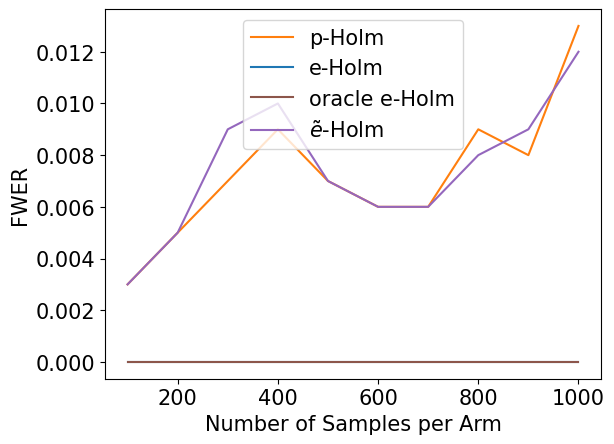

In [ ]:
plt.rcParams.update({'font.size': 15})
methods = ['p', 'e', 'oracle e', r"$\tilde e$"]
colors = ['C1', 'C0', 'C5', 'C4']
for i in [0,1,2,3]:
  plt.plot(num_per_arms, fwers[:,i], label = f'{methods[i]}-Holm', color = colors[i])
  plt.xlabel('Number of Samples per Arm')
  plt.ylabel('FWER')
  plt.legend()

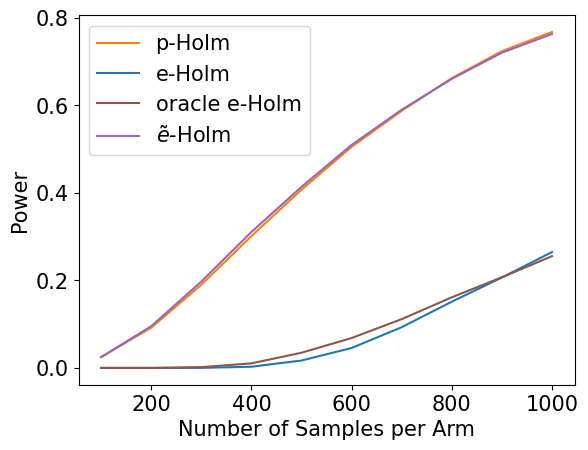

In [ ]:
plt.rcParams.update({'font.size': 15})
for i in [0,1,2,3]:
  plt.plot(num_per_arms, powers[:,i], label = f'{methods[i]}-Holm', color = colors[i])
  plt.xlabel('Number of Samples per Arm')
  plt.ylabel('Power')
  plt.legend()

## Plotting the calibrated and actual levels for pseudo e-Holm

In [ ]:
table = [
    {"K": 2,  "alpha_prime": 0.04603505936888031,  "B_K_0_05": 0.0545806884765625},
    {"K": 5,  "alpha_prime": 0.04254959900789127,  "B_K_0_05": 0.06003761291503906},
    {"K": 10, "alpha_prime": 0.04064557041798585,  "B_K_0_05": 0.06389808654785156},
    {"K": 15, "alpha_prime": 0.039745662809007556, "B_K_0_05": 0.0660247802734375},
    {"K": 20, "alpha_prime": 0.039179155235198486, "B_K_0_05": 0.06753063201904297},
    {"K": 25, "alpha_prime": 0.03874065902712082,  "B_K_0_05": 0.06882762908935547},
    {"K": 30, "alpha_prime": 0.03839911774692701,  "B_K_0_05": 0.06985950469970703},
    {"K": 35, "alpha_prime": 0.038165200607615836, "B_K_0_05": 0.07068061828613281},
    {"K": 40, "alpha_prime": 0.037990017431378836, "B_K_0_05": 0.07134342193603516},
    {"K": 45, "alpha_prime": 0.03784392482131144,  "B_K_0_05": 0.07204627990722656},
    {"K": 50, "alpha_prime": 0.03763148569601143,  "B_K_0_05": 0.0725393295288086},
]

In [ ]:
alpha_prime = table[10]['alpha_prime']

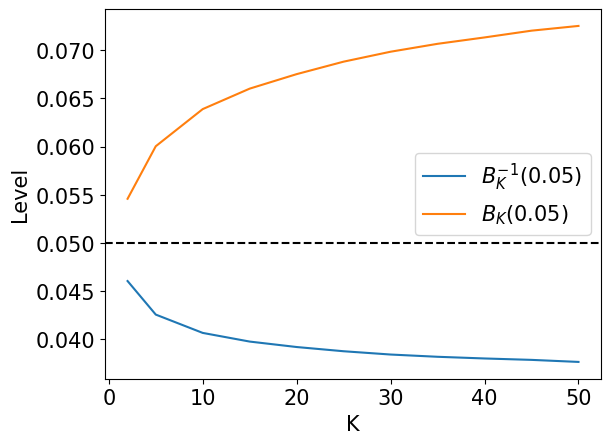

In [ ]:
Ks = [2, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50]

plt.rcParams.update({'font.size': 15})
plt.plot(Ks, [table[i]['alpha_prime'] for i in range(11)], color = 'C0', label = r'$B_K^{-1}(0.05)$')
plt.plot(Ks, [table[i]['B_K_0_05'] for i in range(11)], color = 'C1', label = r'$B_K(0.05)$')
plt.axhline(0.05, linestyle = 'dashed', color = 'black')
plt.xlabel('K')
plt.ylabel('Level')
plt.legend()
plt.show()
